# Financial statements of the 100 biggest US companies: analysis of the dbt marts

**Objective:** use the tables built by the pipeline (SEC XBRL data, DuckDB and dbt) to answer some questions: how profitable is each sector, how did margins change after 2021, who generates more free cash flow, and what data quality problems the tests found.

Before running this notebook: `python ingest/download_sec.py` and `dbt build --profiles-dir .`

Libraries of the project: `duckdb`, `pandas`, `matplotlib` and `seaborn`.

## Part 1. Connection to the DuckDB database

In [1]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
con = duckdb.connect("data/sec_financials.duckdb", read_only=True)
con.sql("show tables").df()

,name
0,fct_annual_financials
1,fct_financial_ratios
2,int_annual_values
3,stg_companies
4,stg_facts


In [2]:
con.sql("""
    select count(*) as rows, count(distinct cik) as companies, min(calendar_year) as first_year, max(calendar_year) as last_year
    from fct_annual_financials
""").df()

,rows,companies,first_year,last_year
0,1173,82,2010,2025


## Part 2. Coverage of each line item

Not every company reports every concept with the same tag, so first we check how complete the mart is.

In [3]:
cobertura = con.sql("""
    select calendar_year,
           count(*) as companies,
           round(avg(case when revenue is not null then 1 else 0 end), 2) as revenue,
           round(avg(case when net_income is not null then 1 else 0 end), 2) as net_income,
           round(avg(case when equity is not null then 1 else 0 end), 2) as equity,
           round(avg(case when operating_cash_flow is not null then 1 else 0 end), 2) as operating_cash_flow
    from fct_annual_financials
    group by 1 order by 1
""").df()
cobertura.tail(8)

,calendar_year,companies,revenue,net_income,equity,operating_cash_flow
8,2018,75,0.93,0.91,0.99,0.95
9,2019,75,0.96,0.92,0.99,0.96
10,2020,75,0.96,0.92,0.99,0.97
11,2021,78,0.94,0.97,0.97,0.94
12,2022,78,0.96,1.00,0.99,0.97
13,2023,79,0.95,0.99,0.99,0.99
14,2024,80,0.95,0.99,0.99,0.99
15,2025,80,0.94,0.96,0.99,0.98


## Part 3. Profitability by sector (2025)

In [4]:
sector = con.sql("""
    select sector,
           count(*) as companies,
           median(net_margin) as median_net_margin,
           median(operating_margin) as median_operating_margin,
           median(roe) as median_roe,
           sum(revenue) / 1e9 as revenue_bn
    from fct_financial_ratios
    where calendar_year = 2025 and revenue is not null
    group by 1
    order by median_net_margin desc
""").df()
sector.round(3)

,sector,companies,median_net_margin,median_operating_margin,median_roe,revenue_bn
0,Software and internet,7,0.301,0.316,0.294,1010.439
1,Other,7,0.291,0.402,0.428,398.730
2,Banks and finance,8,0.259,0.291,0.129,658.916
3,Health care,8,0.245,0.247,0.387,458.644
4,Manufacturing,15,0.185,0.208,0.398,784.450
5,Technology hardware,17,0.182,0.264,0.193,1191.278
6,Telecom and media,3,0.127,0.207,0.179,352.148
7,Insurance,2,0.104,0.042,0.110,819.011
8,Energy,2,0.100,NaN,0.098,247.975
9,Real estate and holdings,1,0.086,NaN,0.025,10.838


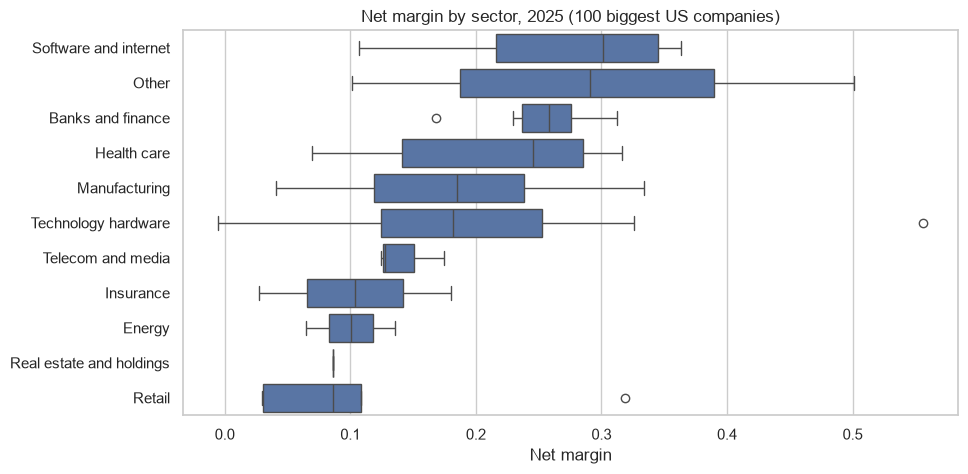

In [5]:
r = con.sql("""
    select sector, net_margin
    from fct_financial_ratios
    where calendar_year = 2025 and net_margin between -0.5 and 0.8
""").df()
plt.figure(figsize=(10, 5))
orden = r.groupby("sector")["net_margin"].median().sort_values(ascending=False).index
sns.boxplot(data=r, y="sector", x="net_margin", order=orden)
plt.title("Net margin by sector, 2025 (100 biggest US companies)")
plt.xlabel("Net margin")
plt.ylabel("")
plt.savefig("figures/net_margin_by_sector.png", bbox_inches="tight")
plt.show()

## Part 4. Evolution of margins

Median net margin each year, for the companies that report revenue.

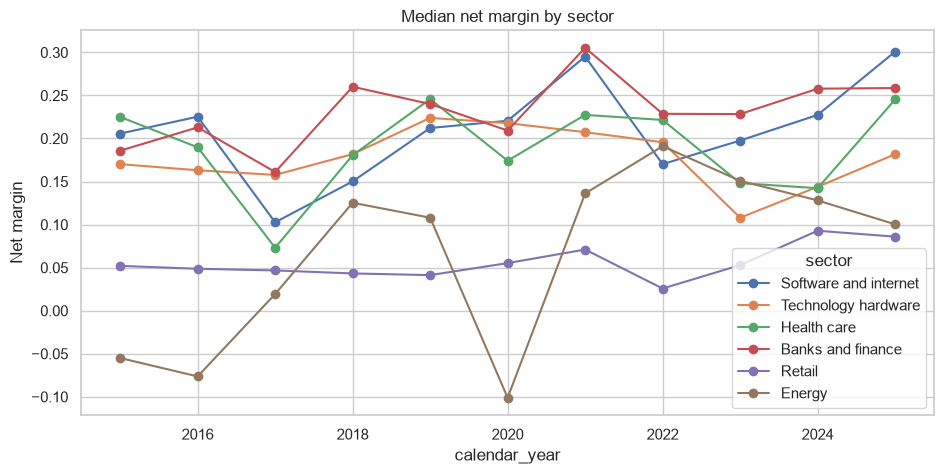

In [6]:
evol = con.sql("""
    select calendar_year, sector, median(net_margin) as net_margin
    from fct_financial_ratios
    where revenue is not null and calendar_year >= 2015
    group by 1, 2
""").df()
piv = evol.pivot(index="calendar_year", columns="sector", values="net_margin")
principales = ["Software and internet", "Technology hardware", "Health care", "Banks and finance", "Retail", "Energy"]
piv[[c for c in principales if c in piv.columns]].plot(figsize=(11, 5), marker="o")
plt.title("Median net margin by sector")
plt.ylabel("Net margin")
plt.savefig("figures/margin_evolution.png", bbox_inches="tight")
plt.show()

## Part 5. Top companies by free cash flow (2025)

In [7]:
con.sql("""
    select ticker, name, sector,
           round(revenue / 1e9, 1) as revenue_bn,
           round(free_cash_flow / 1e9, 1) as fcf_bn,
           round(net_margin, 3) as net_margin,
           round(roe, 3) as roe,
           round(revenue_growth, 3) as revenue_growth
    from fct_financial_ratios
    where calendar_year = 2025 and free_cash_flow is not null
    order by free_cash_flow desc
    limit 15
""").df()

,ticker,name,sector,revenue_bn,fcf_bn,net_margin,roe,revenue_growth
0,AMZN,AMAZON COM INC,Retail,716.9,139.5,0.108,0.223,0.124
1,NVDA,NVIDIA CORP,Technology hardware,215.9,102.7,0.556,1.015,0.655
2,AAPL,Apple Inc.,Technology hardware,416.2,98.8,0.269,1.446,0.064
3,GOOGL,Alphabet Inc.,Software and internet,402.8,73.3,0.328,0.357,0.151
4,MSFT,MICROSOFT CORP,Software and internet,281.7,71.6,0.361,0.294,0.149
5,META,"Meta Platforms, Inc.",Software and internet,201.0,46.1,0.301,0.302,0.222
6,T,AT&T INC.,Telecom and media,125.6,40.3,0.175,0.179,0.027
7,VZ,VERIZON COMMUNICATIONS INC,Telecom and media,138.2,37.1,0.127,0.171,0.025
8,CVX,CHEVRON CORP,Energy,189.0,33.9,0.065,0.073,-0.068
9,AVGO,Broadcom Inc.,Technology hardware,63.9,26.9,NaN,NaN,0.239


## Part 6. Revenue growth vs margin

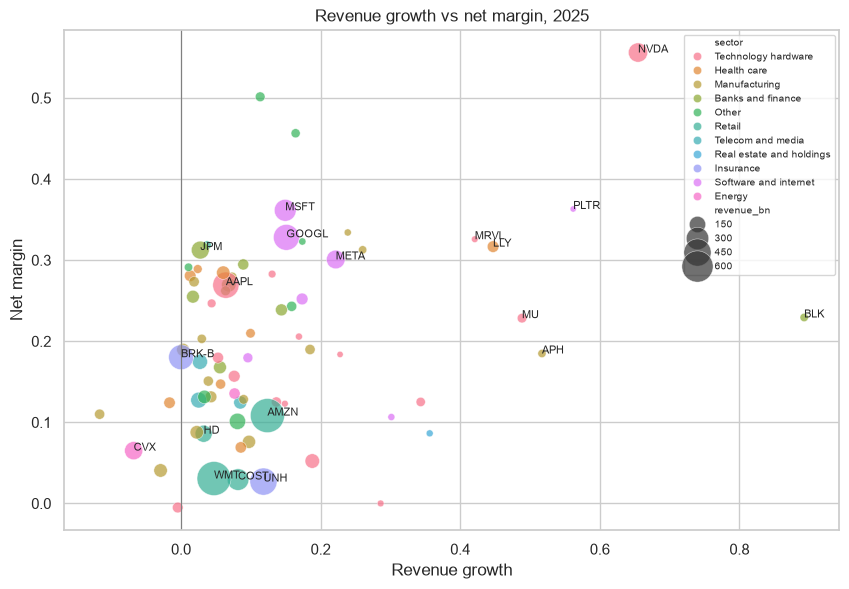

In [8]:
g = con.sql("""
    select ticker, sector, revenue_growth, net_margin, revenue / 1e9 as revenue_bn
    from fct_financial_ratios
    where calendar_year = 2025 and revenue_growth between -0.5 and 1.5 and net_margin between -0.3 and 0.7
""").df()
plt.figure(figsize=(10, 6.5))
sns.scatterplot(data=g, x="revenue_growth", y="net_margin", hue="sector", size="revenue_bn", sizes=(20, 600), alpha=0.7)
for _, fila in g.iterrows():
    if fila["revenue_bn"] > 150 or fila["revenue_growth"] > 0.4:
        plt.annotate(fila["ticker"], (fila["revenue_growth"], fila["net_margin"]), fontsize=8)
plt.axvline(0, color="grey", lw=0.8)
plt.title("Revenue growth vs net margin, 2025")
plt.xlabel("Revenue growth")
plt.ylabel("Net margin")
plt.legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.savefig("figures/growth_vs_margin.png", bbox_inches="tight")
plt.show()

## Part 7. What the data quality tests found

The test `assert_balance_sheet_identity` checks that assets = liabilities + equity with 5% of tolerance. These are the rows that break it:

In [9]:
problemas = con.sql("""
    select ticker, calendar_year, round(total_assets / 1e9, 1) as assets_bn, round(total_liabilities / 1e9, 1) as liabilities_bn,
           round(equity / 1e9, 1) as equity_bn,
           round(abs(total_assets - total_liabilities - equity) / total_assets, 3) as gap
    from fct_annual_financials
    where total_assets > 0 and total_liabilities is not null and equity is not null
      and abs(total_assets - total_liabilities - equity) / total_assets > 0.05
    order by gap desc
""").df()
print("Rows that break the identity:", len(problemas), "of", con.sql("select count(*) from fct_annual_financials where total_liabilities is not null and equity is not null").fetchone()[0])
problemas.head(12)

Rows that break the identity: 22 of 758


,ticker,calendar_year,assets_bn,liabilities_bn,equity_bn,gap
0,TMUS,2010,7.9,5.4,20.5,2.267
1,TMUS,2011,9.5,6.6,15.8,1.356
2,PLTR,2019,1.6,1.4,-2.0,1.335
3,CRWD,2018,0.4,0.4,-0.5,1.288
4,TMUS,2012,33.6,6.8,6.1,0.615
5,MU,2010,14.6,4.6,8.2,0.121
6,MU,2011,14.2,4.5,8.3,0.101
7,GE,2018,311.1,259.6,31.0,0.066
8,NEE,2020,127.7,82.8,36.5,0.066
9,NEE,2023,177.5,118.5,47.5,0.065


The biggest gaps come from three cases: companies before their IPO with **temporary equity** (redeemable preferred shares outside equity, like Palantir 2019 and CrowdStrike 2018), companies that report equity without minority interests (NextEra), and old filings of T-Mobile from before the merger with MetroPCS where the tags do not match. They are not errors of the pipeline but of the definitions, so we keep the test as a warning and document the cases.